<a href="https://colab.research.google.com/github/jaslindoniya/DL-NLP-Text-classifier/blob/main/DL_NLP_Text_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Shape: (1000, 26)
Epoch 1 - Train:0.6938 Val:0.6990
Epoch 2 - Train:0.6930 Val:0.6977
Epoch 3 - Train:0.6914 Val:0.6964
Epoch 4 - Train:0.6904 Val:0.6950
Epoch 5 - Train:0.6891 Val:0.6935
Epoch 6 - Train:0.6883 Val:0.6920
Epoch 7 - Train:0.6860 Val:0.6905
Epoch 8 - Train:0.6859 Val:0.6890
Epoch 9 - Train:0.6837 Val:0.6874
Epoch 10 - Train:0.6816 Val:0.6857
Epoch 11 - Train:0.6807 Val:0.6838
Epoch 12 - Train:0.6793 Val:0.6818
Epoch 13 - Train:0.6777 Val:0.6798
Epoch 14 - Train:0.6756 Val:0.6777
Epoch 15 - Train:0.6742 Val:0.6755


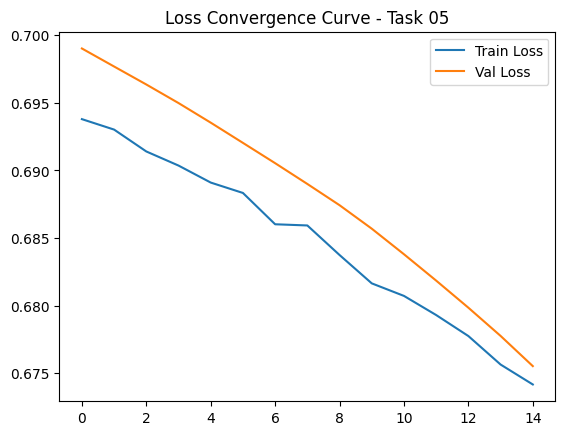


Task 05 Completed!
I love this -> 0.48 confidence
free lottery spam -> 0.46 confidence


In [8]:
import pandas as pd, torch, torch.nn as nn, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score

texts = ['I love this product amazing','Worst purchase ever hate','Best service very happy','spam buy now free money','Excellent work loved it','Click here to win lottery spam','I am very satisfied','Terrible not good','Free offer just for you spam','Superb experience will buy again']*100
labels = [1,0,1,0,1,0,1,0,0,1]*100
df = pd.DataFrame({'text':texts,'label':labels})

vectorizer = TfidfVectorizer(max_features=100, stop_words='english')
X = vectorizer.fit_transform(df['text']).toarray()
y = df['label'].values
print(f"Shape: {X.shape}")

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)
X_train_t = torch.FloatTensor(X_train)
y_train_t = torch.FloatTensor(y_train).view(-1,1)
X_val_t = torch.FloatTensor(X_val)
y_val_t = torch.FloatTensor(y_val).view(-1,1)

class NLPClassifier(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 1)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.3)
    def forward(self, x):
        x = self.dropout(self.relu(self.fc1(x)))
        x = self.dropout(self.relu(self.fc2(x)))
        return torch.sigmoid(self.fc3(x))

model = NLPClassifier(X.shape[1])
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

train_loss, val_loss = [], []
for epoch in range(15):
    model.train()
    optimizer.zero_grad()
    out = model(X_train_t)
    loss = criterion(out, y_train_t)
    loss.backward()
    optimizer.step()
    model.eval()
    with torch.no_grad():
        v_out = model(X_val_t)
        v_loss = criterion(v_out, y_val_t)
    train_loss.append(loss.item())
    val_loss.append(v_loss.item())
    print(f"Epoch {epoch+1} - Train:{loss.item():.4f} Val:{v_loss.item():.4f}")

plt.plot(train_loss, label='Train Loss')
plt.plot(val_loss, label='Val Loss')
plt.title('Loss Convergence Curve - Task 05')
plt.legend()
plt.show()

print("\nTask 05 Completed!")
# Sample test
test = vectorizer.transform(["I love this","free lottery spam"]).toarray()
with torch.no_grad():
    preds = model(torch.FloatTensor(test))
    for t,p in zip(["I love this","free lottery spam"], preds):
        print(f"{t} -> {p.item():.2f} confidence")